# **Lab 2: Logistic regression — from EDA to nonlinear decision boundaries**

[Open the public notebook in Google Colab](https://colab.research.google.com/github/avkornaev/Intro-to-ML-2026/blob/main/labs/02-logistic-regression.ipynb)

**Expected runtime:** 90 minutes  
**Maximum score:** 4 points  
**Required work:** eight `TODO(student)` tasks and seven interpretation questions

If Colab cannot open the repository directly, download `02-logistic-regression.ipynb` from the course site, open [Google Colab](https://colab.research.google.com/), and choose **File → Upload notebook**. Save your own copy before editing.

This lab was developed by **Alexei Kornaev**, with AI-assisted drafting and review using ChatGPT (OpenAI). The instructor retains responsibility for the learning design, technical accuracy, and assessment.

## **1. The question we will investigate**

Lab 1 introduced the complete learning loop with a line. This time the output is a class: **is a tumour malignant or benign?** We will keep the model simple and vary the representation presented to it.

We will compare four pipelines:

| Pipeline | Representation seen by logistic regression | Main question |
|---|---|---|
| A | all 30 raw features | What happens when feature scales differ greatly? |
| B | all 30 standardized features | Does scaling change optimization? |
| C | two standardized principal-component scores | What is lost when 30 dimensions become two? |
| D | standardized $u_1,u_2,u_1^2,u_1u_2,u_2^2$ | Can a nonlinear representation help in the same PCA plane? |

Every model is PyTorch logistic regression. Pipeline D is still **linear in its trainable parameters**, but its quadratic inputs create a nonlinear boundary in the original PCA plane.

### *Learning objectives*

By the end, you should be able to:

- connect training-data EDA to testable modelling hypotheses;
- explain why preprocessing must be fitted on training data only;
- derive the gradient of binary cross-entropy for logistic regression and verify it with autograd;
- implement a `Dataset`, `DataLoader`, logits-based BCE loss, optimizer, and training loop;
- distinguish optimization under a fixed budget from predictive performance;
- explain PCA as a variance-preserving representation that does not optimize class separation;
- explain how a model linear in its parameters can draw a nonlinear boundary;
- use validation to select a pipeline and reserve test data for one final evaluation.

### *Chats are tutors, not solution generators*

You may use a chat assistant for explanations, incremental hints, and debugging. You are responsible for **every submitted line**, every result, and every written answer. During the lab defence, you may be asked to modify or explain your code.

<details>
<summary><strong>Copy this as the first message to a chat, together with the notebook</strong></summary>

```text
You are my tutor for an assessed introductory machine-learning lab on logistic regression. Work in help-me mode.

Help me understand the notebook through explanations, incremental hints, guiding questions, and debugging. Do not complete TODO(student) tasks, write full assessed cells, or answer the final interpretation questions for me. Begin by asking which task I am attempting, what I expect the code to do, and what I have tried.

Give one small hint at a time. If code is necessary, show only the smallest illustrative fragment, not a complete answer. Ask me to predict tensor shapes and results before running code. When debugging, help me identify the cause and let me make the correction. After each step, check my understanding with a brief question.

Pay particular attention to train/validation/test separation, fitting preprocessing only on training data, logits versus probabilities, BCEWithLogitsLoss, tensor shapes, gradients, Dataset/DataLoader, learning curves, PCA, polynomial features, decision boundaries, and classification metrics. Never suggest weakening an assertion, changing the split, or using test results to choose a model.

I am responsible for testing, understanding, and explaining every submitted line and conclusion.
```

Never paste passwords, tokens, private links, personal data, or identifiable patient information into a chat.

</details>

## **2. Setup and Aux. Functions**

Google Colab normally includes the required packages. In another environment, a notebook command begins with `!`, for example:

```python
# Uncomment only if a package is missing:
# !pip install torch scikit-learn pandas matplotlib seaborn
```

The next cells contain imports and supplied plotting/reporting helpers. They keep repetitive presentation code out of the way; the learning tasks—gradients, data loading, model, loss, and training—remain visible later.

In [37]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

sns.set_theme(style="whitegrid", context="notebook")
DEVICE = torch.device("cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.12.0 | device: cpu


In [38]:
# Aux. Functions: supplied evaluation and plotting code.
def as_float_tensor(values):
    return torch.as_tensor(values, dtype=torch.float32, device=DEVICE)


def predict_probabilities(model, features):
    model.eval()
    with torch.no_grad():
        logits = model(as_float_tensor(features)).squeeze(1)
        return torch.sigmoid(logits).cpu().numpy()


def classification_metrics(targets, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(targets, predictions),
        "malignant recall": recall_score(targets, predictions),
        "ROC AUC": roc_auc_score(targets, probabilities),
    }


def plot_histories(histories):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
    for ax, (name, history) in zip(axes.flat, histories.items()):
        ax.plot(history["train"], label="training")
        ax.plot(history["validation"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls=":", lw=1,
                   label="selected checkpoint")
        ax.set(title=name, xlabel="epoch", ylabel="BCE loss", yscale="log")
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle("Same training budget; different representations and dynamics", y=1.02)
    plt.tight_layout()
    plt.show()


def plot_boundary(ax, model, plane_transform, train_plane, train_targets,
                  val_plane, val_targets, title):
    padding = 1.0
    x_min, x_max = train_plane[:, 0].min() - padding, train_plane[:, 0].max() + padding
    y_min, y_max = train_plane[:, 1].min() - padding, train_plane[:, 1].max() + padding
    gx, gy = np.meshgrid(np.linspace(x_min, x_max, 260),
                         np.linspace(y_min, y_max, 260))
    grid = np.column_stack([gx.ravel(), gy.ravel()])
    probabilities = predict_probabilities(model, plane_transform(grid)).reshape(gx.shape)
    ax.contourf(gx, gy, probabilities, levels=np.linspace(0, 1, 11),
                cmap="RdBu_r", alpha=.28)
    ax.contour(gx, gy, probabilities, levels=[.5], colors="black", linewidths=2)
    ax.scatter(train_plane[:, 0], train_plane[:, 1], c=train_targets,
               cmap="RdBu_r", s=17, alpha=.42, label="training")
    ax.scatter(val_plane[:, 0], val_plane[:, 1], c=val_targets,
               cmap="RdBu_r", marker="x", s=42, linewidths=1.3, label="validation")
    ax.set(title=title, xlabel="$u_1$", ylabel="$u_2$")

## **3. Data first: a fixed and honest split**

The Breast Cancer Wisconsin Diagnostic dataset contains **569 samples** and **30 continuous features** computed from digitized images of a fine-needle aspirate of a breast mass. Features summarize properties such as radius, texture, perimeter, area, smoothness, compactness, concavity, symmetry, and fractal dimension.

Scikit-learn encodes malignant as 0 and benign as 1. We deliberately reverse this:

$y=1$ means **malignant** (the positive class), and $y=0$ means **benign**.

This makes malignant recall easy to interpret: among malignant cases, what fraction did the model identify?

In [39]:
cancer = load_breast_cancer(as_frame=True)
X_all = cancer.data.copy()
y_all = (cancer.target == 0).astype(np.float32).rename("malignant")

print("original target names:", list(cancer.target_names))
print("features:", X_all.shape, "| target:", y_all.shape)
display(X_all.head(3))

assert X_all.shape == (569, 30)
assert set(y_all.unique()) == {0.0, 1.0}

original target names: [np.str_('malignant'), np.str_('benign')]
features: (569, 30) | target: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [40]:
# First isolate the test set. Then split the remaining development data.
X_development, X_test, y_development, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.25,
    stratify=y_development, random_state=SEED
)

split_summary = pd.DataFrame({
    "samples": [len(X_train), len(X_val)],
    "malignant proportion": [y_train.mean(), y_val.mean()],
}, index=["training", "validation"])
display(split_summary.style.format({"malignant proportion": "{:.3f}"}))
print("reserved test samples:", len(X_test), "(targets remain uninspected)")

assert len(X_train) + len(X_val) + len(X_test) == 569
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

,samples,malignant proportion
training,341,0.372
validation,114,0.377


reserved test samples: 114 (targets remain uninspected)


The **training set** may inform plots, transformations, and parameter updates. The **validation set** may inform pipeline selection. The **test set** is now closed until the final model has been selected.

Stratification keeps the class proportions similar; it does not make the sets identical, and it does not remove the need for appropriate metrics.

## **4. Model-informing EDA on training data only**

EDA is not decoration. Each observation should lead to a modelling hypothesis that we can check experimentally.

### *Data quality and class balance*

,value
training samples,341
features,30
missing values,0
infinite values,0
duplicated rows,0


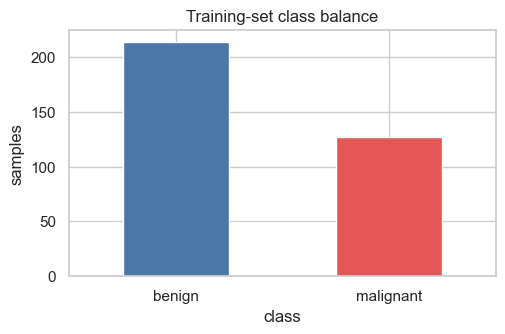

In [41]:
quality = pd.Series({
    "training samples": len(X_train),
    "features": X_train.shape[1],
    "missing values": int(X_train.isna().sum().sum()),
    "infinite values": int(np.isinf(X_train.to_numpy()).sum()),
    "duplicated rows": int(X_train.duplicated().sum()),
})
display(quality.to_frame("value"))

class_counts = y_train.map({0.0: "benign", 1.0: "malignant"}).value_counts()
ax = class_counts.reindex(["benign", "malignant"]).plot.bar(
    color=["#4C78A8", "#E45756"], rot=0, figsize=(5.5, 3.2)
)
ax.set(title="Training-set class balance", xlabel="class", ylabel="samples")
plt.show()

assert quality["missing values"] == 0
assert quality["infinite values"] == 0

### *Feature scales*

,range,standard deviation
fractal dimension error,0.022,0.00259
smoothness error,0.0294,0.00297
mean area,2.36e+03,372
worst area,4.07e+03,592


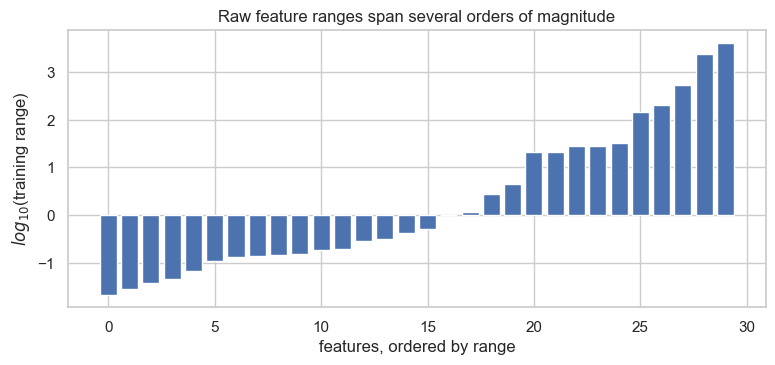

In [42]:
feature_ranges = X_train.max() - X_train.min()
feature_std = X_train.std()
scale_table = pd.DataFrame({"range": feature_ranges, "standard deviation": feature_std})
display(scale_table.sort_values("range").iloc[[0, 1, -2, -1]].style.format("{:.3g}"))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(np.arange(len(feature_ranges)), np.log10(feature_ranges.sort_values()))
ax.set(title="Raw feature ranges span several orders of magnitude",
       xlabel="features, ordered by range", ylabel="$log_{10}$(training range)")
plt.show()

Gradient descent uses one learning rate for every coefficient. When one feature varies near $10^{-2}$ and another near $10^3$, the corresponding gradients can have very different scales. This suggests a testable hypothesis: **standardization may make optimization more stable under the same budget**.

### *Distributions and correlations*

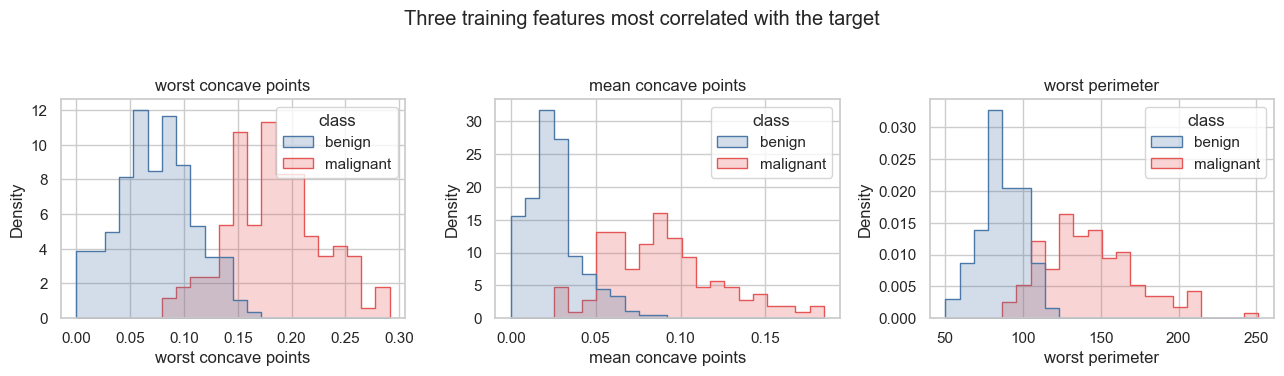

In [43]:
eda_frame = X_train.copy()
eda_frame["malignant"] = y_train
eda_frame["class"] = y_train.map({0.0: "benign", 1.0: "malignant"})
target_correlations = eda_frame.corr(numeric_only=True)["malignant"].drop("malignant")
strongest_features = target_correlations.abs().nlargest(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, feature in zip(axes, strongest_features):
    sns.histplot(data=eda_frame, x=feature, hue="class", bins=22,
                 stat="density", common_norm=False, element="step", ax=ax,
                 palette={"benign": "#4C78A8", "malignant": "#E45756"})
    ax.set_title(feature)
fig.suptitle("Three training features most correlated with the target", y=1.04)
plt.tight_layout()
plt.show()

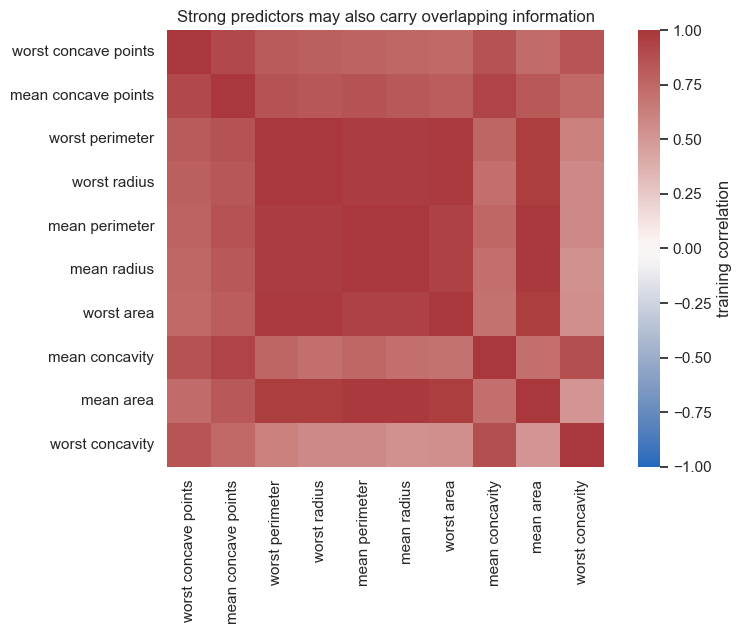

In [44]:
correlated_features = target_correlations.abs().nlargest(10).index
correlation_matrix = X_train[correlated_features].corr()

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(correlation_matrix, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "training correlation"})
plt.title("Strong predictors may also carry overlapping information")
plt.tight_layout()
plt.show()

### *Task 1/8 — Turn EDA into hypotheses*

Write three concise predictions **before** training the models. Refer to evidence above.

1. **A versus B — scaling and optimization:** 

Without scaling feature with large numbers can interfere with learning, because it can cause a sharp change in its weight during training, which will lead to an increase in error

2. **B versus C — dimensionality reduction:** 

I think B will perform better because PCA may remove some useful information, making it harder for the model to distinguish between benign and malignant tumours.

3. **C versus D — nonlinear representation:** 

I belive that D will be better because the model can fit the data beter using additional features that may help differentiate. classes.

These are hypotheses, not promises. In particular, polynomial features need not improve validation performance.

## **5. Logistic regression: data → model → loss → optimizer**

For a feature vector $x_i$, logistic regression produces a **logit**

$$z_i=x_i^T w+b,$$

then converts it to a probability with the sigmoid:

$$p_i=\sigma(z_i)=\frac{1}{1+e^{-z_i}}.$$

At threshold 0.5, $p_i\geq0.5$ predicts malignant. Because $\sigma(0)=0.5$, the decision boundary is exactly where $z_i=0$.

Binary cross-entropy averages the Bernoulli negative log-likelihood:

$$L=-\frac{1}{N}\sum_i\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].$$

We will use `BCEWithLogitsLoss`, which accepts logits and combines the sigmoid and BCE calculations in a numerically stable way. Do **not** put a sigmoid layer inside the model during training.

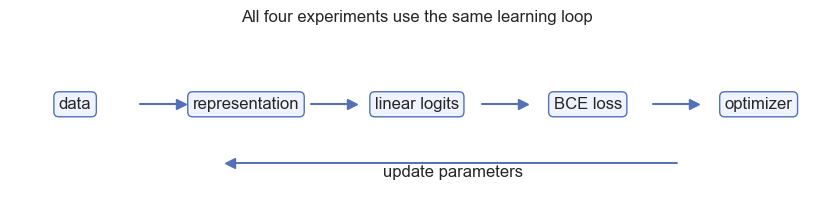

In [45]:
fig, ax = plt.subplots(figsize=(10.5, 2.3))
ax.axis("off")
labels = ["data", "representation", "linear logits", "BCE loss", "optimizer"]
positions = np.linspace(.08, .92, len(labels))
for x, label in zip(positions, labels):
    ax.text(x, .58, label, ha="center", va="center",
            bbox=dict(boxstyle="round", fc="#EEF3FF", ec="#5271B8"))
for left, right in zip(positions[:-1], positions[1:]):
    ax.plot([left + .08, right - .08], [.58, .58], color="#5271B8", lw=1.5)
    ax.plot(right - .08, .58, marker=">", color="#5271B8", ms=7)
ax.plot([.82, .27], [.25, .25], color="#5271B8", lw=1.4)
ax.plot(.27, .25, marker="<", color="#5271B8", ms=7)
ax.text(.545, .17, "update parameters", ha="center")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("All four experiments use the same learning loop")
plt.show()

### *Analytical gradient*

For a batch matrix $X$ with one sample per row, the BCE gradients simplify to

$$\frac{\partial L}{\partial w}=\frac{1}{N}X^T(p-y),$$

$$\frac{\partial L}{\partial b}=\frac{1}{N}\sum_i(p_i-y_i).$$

The residual is now **probability minus binary target**. The feature matrix redistributes that residual to the coefficients.

### *Task 2/8 — Calculate the analytical gradients with tensors*

In [46]:
def analytical_logistic_gradients(features, targets, weights, bias):
    # features: [N, D], targets: [N, 1], weights: [D, 1], bias: [1]
    # TODO(student): compute logits, probabilities, dL/dw, and dL/db.
    
    z = features @ weights + bias
    p = 1 / (1 + torch.exp(-z))
    dif = p - targets
    N = features.shape[0]

    dl_dw = (1 / N) * features.T @ dif
    dl_db = dif.mean(dim=0)

    return dl_dw, dl_db

In [47]:
X_check = torch.tensor([[1.0, -1.0], [0.5, 2.0], [-1.5, 0.3]], dtype=torch.float64)
y_check = torch.tensor([[1.0], [0.0], [1.0]], dtype=torch.float64)
w_check = torch.tensor([[0.2], [-0.4]], dtype=torch.float64, requires_grad=True)
b_check = torch.tensor([0.1], dtype=torch.float64, requires_grad=True)

manual_dw, manual_db = analytical_logistic_gradients(
    X_check, y_check, w_check.detach(), b_check.detach()
)
autograd_loss = nn.BCEWithLogitsLoss()(X_check @ w_check + b_check, y_check)
autograd_loss.backward()

assert manual_dw.shape == w_check.shape
assert manual_db.shape == b_check.shape
assert torch.allclose(manual_dw, w_check.grad, atol=1e-10)
assert torch.allclose(manual_db, b_check.grad, atol=1e-10)
print("analytical dL/dw:")
print(manual_dw)
print("autograd dL/dw:")
print(w_check.grad)
print("Task 2 passed: analytical gradients and autograd agree.")

analytical dL/dw:
tensor([[0.2381],
        [0.2889]], dtype=torch.float64)
autograd dL/dw:
tensor([[0.2381],
        [0.2889]], dtype=torch.float64)
Task 2 passed: analytical gradients and autograd agree.


Autograd did not approximate nearby loss values. It differentiated the recorded tensor operations and produced the same gradient at the current parameters.

## **6. Build the reusable PyTorch pipeline**

### *Task 3/8 — Implement a classification Dataset*

In [48]:
class CancerDataset(Dataset):
    def __init__(self, features, targets):
        self.features = as_float_tensor(np.asarray(features))
        self.targets = as_float_tensor(np.asarray(targets)).reshape(-1, 1)
        if len(self.features) != len(self.targets):
            raise ValueError("features and targets must have equal length")

    def __len__(self):
        # TODO(student): return the number of samples.
        return self.features.shape[0]


    def __getitem__(self, index):
        # TODO(student): return one (features, target) pair.
        return self.features[index], self.targets[index]

In [49]:
shape_dataset = CancerDataset(X_train.to_numpy(), y_train.to_numpy())
shape_loader = DataLoader(shape_dataset, batch_size=32, shuffle=False, num_workers=0)
batch_features, batch_targets = next(iter(shape_loader))

assert len(shape_dataset) == len(X_train)
assert batch_features.shape == (32, 30)
assert batch_targets.shape == (32, 1)
print("one batch of inputs:", batch_features.shape)
print("one batch of targets:", batch_targets.shape)
print("one sample:", shape_dataset[0][0].shape, "→", shape_dataset[0][1].shape)

one batch of inputs: torch.Size([32, 30])
one batch of targets: torch.Size([32, 1])
one sample: torch.Size([30]) → torch.Size([1])


`nn.Linear(D, 1)` computes one logit per sample. Its weight has shape `[1, D]`, and its bias has shape `[1]`. With 30 features, that is $30+1=31$ trainable parameters.

### *Task 4/8 — Create the model, logits-based loss, and optimizer*

In [50]:
def make_training_objects(number_of_features, learning_rate):
    torch.manual_seed(SEED)
    # TODO(student): create nn.Linear(D, 1), set its weight and bias to zero,
    # then create BCEWithLogitsLoss and SGD.
    
    model = nn.Linear(number_of_features, 1)
    nn.init.zeros_(model.weight)
    nn.init.zeros_(model.bias)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(model.parameters(), learning_rate)
    return model, criterion, optimizer

In [51]:
model_check, criterion_check, optimizer_check = make_training_objects(30, 0.01)
logits_check = model_check(batch_features)

assert isinstance(model_check, nn.Linear)
assert isinstance(criterion_check, nn.BCEWithLogitsLoss)
assert isinstance(optimizer_check, torch.optim.SGD)
assert all(torch.count_nonzero(parameter) == 0 for parameter in model_check.parameters())
assert logits_check.shape == (32, 1)
assert torch.allclose(logits_check, torch.zeros_like(logits_check))
print("input", batch_features.shape, "→ logits", logits_check.shape)
print("parameters:", sum(parameter.numel() for parameter in model_check.parameters()))
print("zero initialization gives initial probability:", torch.sigmoid(logits_check[0]).item())

input torch.Size([32, 30]) → logits torch.Size([32, 1])
parameters: 31
zero initialization gives initial probability: 0.5


The shapes through one batch are:

$$
[32,30]\;\text{features}
\;\longrightarrow\; nn.Linear(30,1)
\;\longrightarrow\; [32,1]\;\text{logits}
\;\xleftrightarrow{\mathrm{BCE}}\; [32,1]\;\text{targets}.
$$

The first dimension counts samples; the second counts values per sample. BCE compares each sample's one logit with its one binary target.

### *Task 5/8 — Complete one training epoch*

In [52]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, total_samples = 0.0, 0

    for features, targets in loader:
        # TODO(student): logits → loss → zero gradients → backward → step.
        
        logits = model(features)
        loss = criterion(logits, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    

        total_loss += loss.item() * len(features)
        total_samples += len(features)

    return total_loss / total_samples

### *Task 6/8 — Evaluate without updating parameters*

In [53]:
def evaluate_loss(model, loader, criterion):
    # TODO(student): use evaluation mode and torch.no_grad().
    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.no_grad():
        for features, targets in loader:
            logits = model(features)
            loss = criterion(logits, targets)
            total_loss += loss.item() * len(features)
            total_samples += len(features)

    return total_loss / total_samples

In [54]:
# A short behavior test: one epoch should change parameters and reduce loss.
tiny_X = np.array([[-2.0], [-1.0], [1.0], [2.0]], dtype=np.float32)
tiny_y = np.array([0.0, 0.0, 1.0, 1.0], dtype=np.float32)
tiny_dataset = CancerDataset(tiny_X, tiny_y)
tiny_loader = DataLoader(tiny_dataset, batch_size=4, shuffle=False)
tiny_model, tiny_criterion, tiny_optimizer = make_training_objects(1, 0.2)
loss_before = evaluate_loss(tiny_model, tiny_loader, tiny_criterion)
parameters_before = [parameter.detach().clone() for parameter in tiny_model.parameters()]
for _ in range(10):
    train_one_epoch(tiny_model, tiny_loader, tiny_criterion, tiny_optimizer)
loss_after = evaluate_loss(tiny_model, tiny_loader, tiny_criterion)

assert loss_after < loss_before
assert any(not torch.equal(before, after) for before, after in
           zip(parameters_before, tiny_model.parameters()))
print(f"behavior test: BCE {loss_before:.4f} → {loss_after:.4f}")

behavior test: BCE 0.6931 → 0.2361


The supplied experiment runner below repeats your visible training functions. Every pipeline receives the same optimizer, learning rate, batch size, epoch budget, random initialization rule, and checkpoint rule. The best validation-loss checkpoint is retained, but **all models still receive the full budget**.

In [55]:
EPOCHS = 200
BATCH_SIZE = 32
LEARNING_RATE = 0.01
PRINT_EPOCHS = {0, 1, 4, 19, 49, 99, 199}


def fit_model(name, train_features, val_features):
    train_dataset = CancerDataset(train_features, y_train.to_numpy())
    val_dataset = CancerDataset(val_features, y_val.to_numpy())
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=generator, num_workers=0)
    train_eval_loader = DataLoader(train_dataset, batch_size=128, shuffle=False, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=0)

    model, criterion, optimizer = make_training_objects(train_features.shape[1], LEARNING_RATE)
    history = {"train": [], "validation": [], "best_epoch": 0}
    best_val_loss = float("inf")
    best_state = None

    print(f"\n{name}")
    for epoch in range(EPOCHS):
        train_one_epoch(model, train_loader, criterion, optimizer)
        train_loss = evaluate_loss(model, train_eval_loader, criterion)
        val_loss = evaluate_loss(model, val_loader, criterion)
        history["train"].append(train_loss)
        history["validation"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            history["best_epoch"] = epoch
            best_state = {
                key: value.detach().clone() for key, value in model.state_dict().items()
            }
        if epoch in PRINT_EPOCHS:
            print(f"epoch {epoch:3d} | train BCE {train_loss:8.4f} | val BCE {val_loss:8.4f}")

    model.load_state_dict(best_state)
    return model, history

## **7. Build four representations without leakage**

A preprocessing object may **learn** only from `X_train`:

- `fit` learns means, standard deviations, or PCA directions;
- `transform` applies those learned quantities to validation data;
- `fit_transform` on validation or test data would leak information.

### *Task 7/8 — Fit standardization and PCA on training data only*

In [56]:
# A: raw features.
X_train_A = X_train.to_numpy(dtype=np.float32)
X_val_A = X_val.to_numpy(dtype=np.float32)

# B: all standardized features.
feature_scaler = StandardScaler()
# TODO(student): fit on training features; only transform validation features.
X_train_B = feature_scaler.fit_transform(X_train)
X_val_B = feature_scaler.transform(X_val)

# C begins with two PCA scores from the standardized features.
pca = PCA(n_components=2, random_state=SEED)
# TODO(student): fit PCA on X_train_B; only transform X_val_B.
U_train = pca.fit_transform(X_train_B)
U_val = pca.transform(X_val_B)

# Standardize the two scores before logistic regression.
pc_scaler = StandardScaler()
# TODO(student): fit on U_train; only transform U_val.
X_train_C = pc_scaler.fit_transform(U_train)
X_val_C = pc_scaler.transform(U_val)

In [57]:
assert X_train_A.shape == X_train_B.shape == (341, 30)
assert X_val_A.shape == X_val_B.shape == (114, 30)
assert U_train.shape == X_train_C.shape == (341, 2)
assert U_val.shape == X_val_C.shape == (114, 2)
assert np.allclose(X_train_B.mean(axis=0), 0, atol=1e-5)
assert np.allclose(X_train_B.std(axis=0), 1, atol=1e-5)
assert np.allclose(X_train_C.mean(axis=0), 0, atol=1e-5)
assert np.allclose(X_train_C.std(axis=0), 1, atol=1e-5)

explained = pca.explained_variance_ratio_
print(f"PC1 explained variance: {explained[0]:.1%}")
print(f"PC2 explained variance: {explained[1]:.1%}")
print(f"total retained variance: {explained.sum():.1%}")

PC1 explained variance: 44.2%
PC2 explained variance: 19.8%
total retained variance: 64.0%


PCA chooses directions with high **feature variance**, without looking at the class labels. High explained variance does not guarantee high class separation; low-variance directions can still contain predictive information. Comparison B versus C will test how much useful classification information survives this two-dimensional compression.

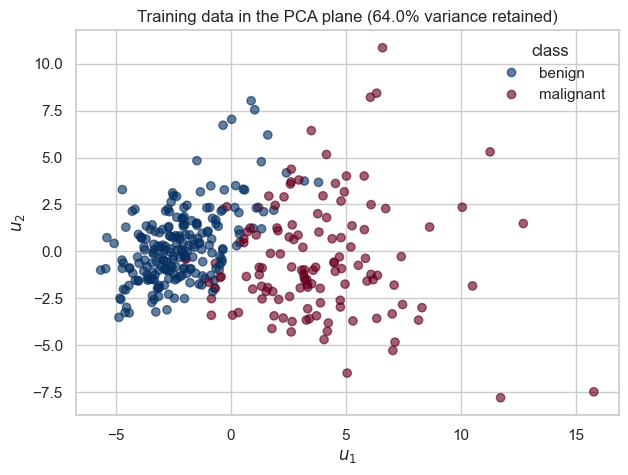

In [58]:
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(U_train[:, 0], U_train[:, 1], c=y_train, cmap="RdBu_r", alpha=.62)
ax.set(title=f"Training data in the PCA plane ({explained.sum():.1%} variance retained)",
       xlabel="$u_1$", ylabel="$u_2$")
handles, _ = scatter.legend_elements()
ax.legend(handles, ["benign", "malignant"], title="class", frameon=False)
plt.show()

### *Task 8/8 — Construct the quadratic representation*

In [59]:
def quadratic_features(two_components):
    u1 = two_components[:, 0]
    u2 = two_components[:, 1]
    # TODO(student): return columns u1, u2, u1**2, u1*u2, u2**2.
    return np.column_stack((u1, u2, u1**2, u1*u2, u2**2))


polynomial_scaler = StandardScaler()
# TODO(student): fit only on quadratic_features(U_train); transform U_val.
X_train_D = polynomial_scaler.fit_transform(quadratic_features(U_train))
X_val_D =  polynomial_scaler.transform(quadratic_features(U_val))

In [60]:
expected_first_row = np.array([
    U_train[0, 0], U_train[0, 1], U_train[0, 0] ** 2,
    U_train[0, 0] * U_train[0, 1], U_train[0, 1] ** 2,
])
assert quadratic_features(U_train).shape == (341, 5)
assert np.allclose(quadratic_features(U_train)[0], expected_first_row)
assert X_train_D.shape == (341, 5) and X_val_D.shape == (114, 5)
assert np.allclose(X_train_D.mean(axis=0), 0, atol=1e-5)
assert np.allclose(X_train_D.std(axis=0), 1, atol=1e-5)
print("D input columns: u1, u2, u1², u1u2, u2²")
print("quadratic input shape:", X_train_D.shape)

D input columns: u1, u2, u1², u1u2, u2²
quadratic input shape: (341, 5)


Pipeline D learns

$$z=\beta_0+\beta_1u_1+\beta_2u_2+\beta_3u_1^2+\beta_4u_1u_2+\beta_5u_2^2.$$

The six $\beta$ values are still linear parameters. Setting $z=0$ produces a quadratic curve in $(u_1,u_2)$, rather than the straight line produced by C.

## **8. Train A–D under one fixed budget**

In [61]:
representations = {
    "A · raw 30D": (X_train_A, X_val_A),
    "B · standardized 30D": (X_train_B, X_val_B),
    "C · standardized PCA 2D": (X_train_C, X_val_C),
    "D · standardized quadratic 5D": (X_train_D, X_val_D),
}

models, histories = {}, {}
for name, (train_representation, val_representation) in representations.items():
    model, history = fit_model(name, train_representation, val_representation)
    models[name] = model
    histories[name] = history

assert set(models) == set(representations)
assert all(len(history["train"]) == EPOCHS for history in histories.values())


A · raw 30D
epoch   0 | train BCE 192.7588 | val BCE 183.1194
epoch   1 | train BCE 180.2455 | val BCE 153.1072
epoch   4 | train BCE 1597.9386 | val BCE 1469.5784
epoch  19 | train BCE  85.6571 | val BCE  47.5786
epoch  49 | train BCE  54.2222 | val BCE  28.6538
epoch  99 | train BCE 209.4496 | val BCE 193.2623
epoch 199 | train BCE  40.2628 | val BCE  26.0677

B · standardized 30D
epoch   0 | train BCE   0.5290 | val BCE   0.5450
epoch   1 | train BCE   0.4379 | val BCE   0.4626
epoch   4 | train BCE   0.3107 | val BCE   0.3468
epoch  19 | train BCE   0.1690 | val BCE   0.2182
epoch  49 | train BCE   0.1121 | val BCE   0.1706
epoch  99 | train BCE   0.0832 | val BCE   0.1518
epoch 199 | train BCE   0.0628 | val BCE   0.1440

C · standardized PCA 2D
epoch   0 | train BCE   0.6750 | val BCE   0.6768
epoch   1 | train BCE   0.6579 | val BCE   0.6614
epoch   4 | train BCE   0.6115 | val BCE   0.6198
epoch  19 | train BCE   0.4609 | val BCE   0.4856
epoch  49 | train BCE   0.3330 | val B

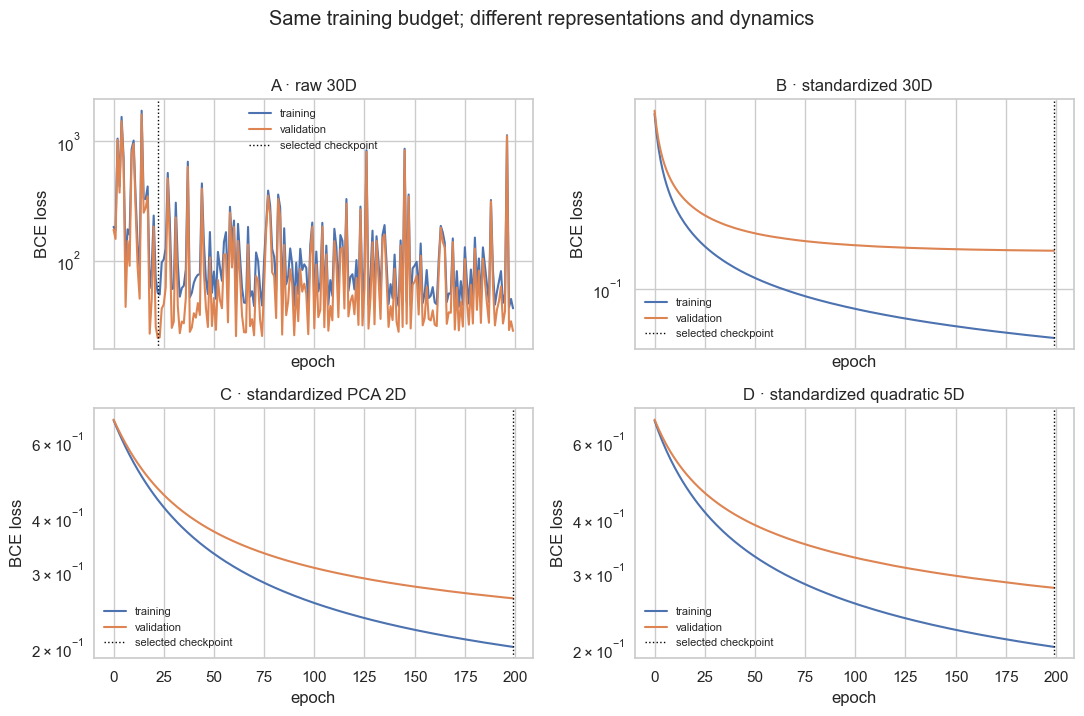

In [62]:
plot_histories(histories)

### *Convergence is not the same as predictive performance*

A learning curve describes what the optimizer achieved under this learning rate and budget. Validation metrics describe predictions made by the selected checkpoint on unseen validation samples. A pipeline can optimize smoothly yet discard useful information; another can have a useful representation but be poorly optimized.

Pipeline A is particularly diagnostic: the same SGD learning rate acts on raw columns with very different scales. Its curve should not be interpreted as proof that raw logistic regression is intrinsically a bad classifier—only as evidence about this optimization configuration.

In [63]:
representation_labels = {
    "A · raw 30D": "30 raw features",
    "B · standardized 30D": "30 standardized features",
    "C · standardized PCA 2D": "2 standardized PCA scores",
    "D · standardized quadratic 5D": "standardized u1, u2, u1², u1u2, u2²",
}
rows = []
for name, (train_representation, val_representation) in representations.items():
    model = models[name]
    train_probabilities = predict_probabilities(model, train_representation)
    val_probabilities = predict_probabilities(model, val_representation)
    train_targets_tensor = as_float_tensor(y_train.to_numpy()).reshape(-1, 1)
    val_targets_tensor = as_float_tensor(y_val.to_numpy()).reshape(-1, 1)
    criterion = nn.BCEWithLogitsLoss()
    with torch.no_grad():
        train_bce = criterion(model(as_float_tensor(train_representation)), train_targets_tensor).item()
        val_bce = criterion(model(as_float_tensor(val_representation)), val_targets_tensor).item()
    metrics = classification_metrics(y_val.to_numpy(), val_probabilities)
    rows.append({
        "pipeline": name,
        "representation": representation_labels[name],
        "parameters": sum(parameter.numel() for parameter in model.parameters()),
        "best epoch": histories[name]["best_epoch"],
        "training BCE": train_bce,
        "validation BCE": val_bce,
        "validation accuracy": metrics["accuracy"],
        "validation malignant recall": metrics["malignant recall"],
        "validation ROC AUC": metrics["ROC AUC"],
    })

comparison = pd.DataFrame(rows).set_index("pipeline")
display(comparison.style.format({
    "training BCE": "{:.4f}", "validation BCE": "{:.4f}",
    "validation accuracy": "{:.3f}",
    "validation malignant recall": "{:.3f}", "validation ROC AUC": "{:.3f}",
}))

assert comparison.shape == (4, 8)
assert comparison.loc["A · raw 30D", "parameters"] == 31
assert comparison.loc["B · standardized 30D", "parameters"] == 31
assert comparison.loc["C · standardized PCA 2D", "parameters"] == 3
assert comparison.loc["D · standardized quadratic 5D", "parameters"] == 6

,representation,parameters,best epoch,training BCE,validation BCE,validation accuracy,validation malignant recall,validation ROC AUC
pipeline,,,,,,,,
A · raw 30D,30 raw features,31,22,54.2594,22.7861,0.930,0.907,0.936
B · standardized 30D,30 standardized features,31,199,0.0628,0.1440,0.947,0.884,0.984
C · standardized PCA 2D,2 standardized PCA scores,3,199,0.2008,0.2603,0.895,0.744,0.973
D · standardized quadratic 5D,"standardized u1, u2, u1², u1u2, u2²",6,199,0.2024,0.2768,0.886,0.721,0.969


### *The exact boundaries of C and D*

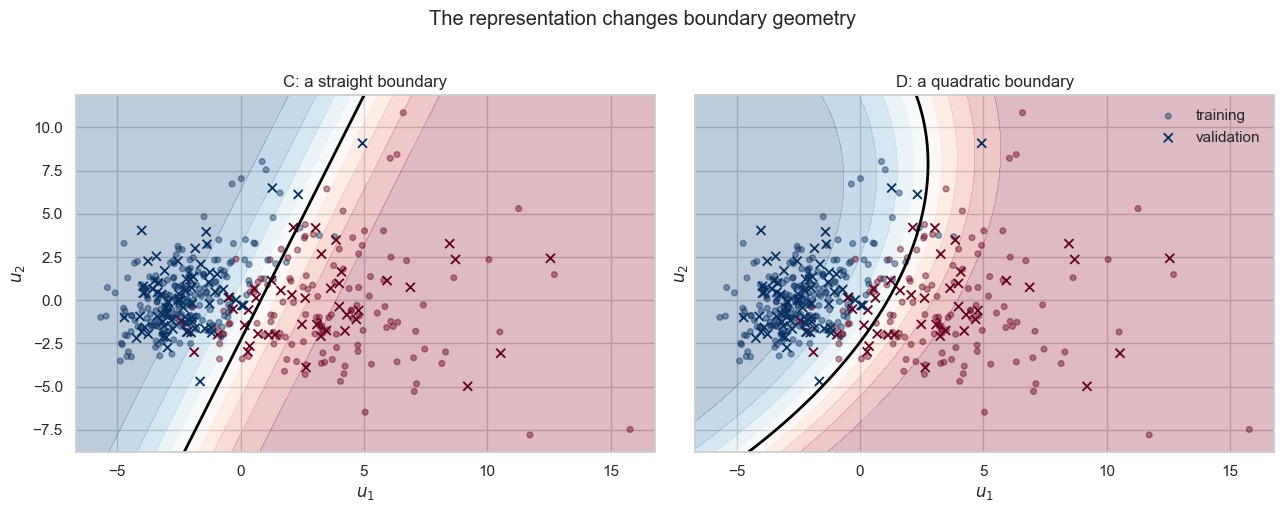

In [64]:
transform_C = lambda plane: pc_scaler.transform(plane).astype(np.float32)
transform_D = lambda plane: polynomial_scaler.transform(
    quadratic_features(plane)
).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
plot_boundary(axes[0], models["C · standardized PCA 2D"], transform_C,
              U_train, y_train.to_numpy(), U_val, y_val.to_numpy(),
              "C: a straight boundary")
plot_boundary(axes[1], models["D · standardized quadratic 5D"], transform_D,
              U_train, y_train.to_numpy(), U_val, y_val.to_numpy(),
              "D: a quadratic boundary")
axes[1].legend(frameon=False, loc="best")
fig.suptitle("The representation changes boundary geometry", y=1.02)
plt.tight_layout()
plt.show()

The black contour is the exact $p=0.5$ boundary of each trained PyTorch model. C can only draw a line in the PCA plane. D can draw a conic curve—but extra flexibility is useful only if it improves validation evidence.

## **9. Select once, then open the test set once**

In [65]:
# Pre-declared decision rule: select the lowest validation BCE.
selected_name = comparison["validation BCE"].idxmin()
selected_model = models[selected_name]
print("Selected from validation evidence:", selected_name)

Selected from validation evidence: B · standardized 30D


The selection rule was fixed before inspecting test performance. We now transform the test set using objects fitted on training data and evaluate **only the selected pipeline**.

In [66]:
# Transform only the selected representation.
if selected_name == "A · raw 30D":
    selected_test_features = X_test.to_numpy(dtype=np.float32)
else:
    standardized_test = feature_scaler.transform(X_test).astype(np.float32)
    if selected_name == "B · standardized 30D":
        selected_test_features = standardized_test
    else:
        test_plane = pca.transform(standardized_test).astype(np.float32)
        if selected_name == "C · standardized PCA 2D":
            selected_test_features = pc_scaler.transform(test_plane).astype(np.float32)
        else:
            selected_test_features = polynomial_scaler.transform(
                quadratic_features(test_plane)
            ).astype(np.float32)
test_probabilities = predict_probabilities(selected_model, selected_test_features)
test_metrics = classification_metrics(y_test.to_numpy(), test_probabilities)
test_targets_tensor = as_float_tensor(y_test.to_numpy()).reshape(-1, 1)
with torch.no_grad():
    test_bce = nn.BCEWithLogitsLoss()(
        selected_model(as_float_tensor(selected_test_features)), test_targets_tensor
    ).item()

final_test_result = pd.Series({
    "pipeline": selected_name,
    "test BCE": test_bce,
    "test accuracy": test_metrics["accuracy"],
    "test malignant recall": test_metrics["malignant recall"],
    "test ROC AUC": test_metrics["ROC AUC"],
}, name="final test evaluation")
display(final_test_result.to_frame("value"))

assert len(test_probabilities) == len(y_test)
assert np.isfinite(test_probabilities).all()
assert ((0 <= test_probabilities) & (test_probabilities <= 1)).all()

,value
pipeline,B · standardized 30D
test BCE,0.084157
test accuracy,0.973684
test malignant recall,0.952381
test ROC AUC,0.998677


## **10. Interpretation questions**

Answer in your own words. Ground every answer in a table, curve, plot, assertion, or tensor shape from your run.

1. What evidence from training-only EDA motivated standardization? Did A versus B support your optimization hypothesis under the fixed budget?
2. Why is `BCEWithLogitsLoss` given logits rather than sigmoid probabilities? What shape did the model produce for one batch?
3. Explain the term $X^T(p-y)/N$ in the analytical gradient. How did the comparison with autograd test your implementation?
4. How much variance did two PCA components retain? Why does that number not tell us how much class-separation information they retained? Use B versus C.
5. Why is D linear in its trainable parameters but nonlinear in the PCA plane? Describe the two plotted boundaries.
6. Did D improve validation performance over C? Explain why the result does not contradict the greater flexibility of D.
7. Which pipeline was selected, what evidence selected it, and what can—and cannot—be concluded from its one-time test result?

**Your answers:**

1. Feature ranges was very different: from 0.022 to 4070. Standardization helped B train more steadily. Its validation BCE was 0.1440, compared with 22.7861 for A.

2. BCEWithLogitsLoss already includes sigmoid and calculates the loss in a numerically stable way. The model output shape was [32, 1]: one logit for each tumour.

3. \(p-y\) is the difference between predicted probabilities and correct labels. Multiplying by \(X^T\) gives the contribution of each feature. Dividing by \(N\) gives the average. The checks showed that my gradients matched autograd.

4. PCA kept 64% of the variance, but it does not use class labels. It may lose information that helps separate the classes. C had a higher validation BCE than B: 0.2603 versus 0.1440.

5. D is linear in its weights, but its features include squares and a product. Therefore, C has a straight decision boundary, while D has a curved boundary.

6. D did not improve validation performance. It is BCE was higher than C: 0.2768 versus 0.2603. Its accuracy, recall, and AUC were also lower

7. B was selected because it had the lowest validation BCE. Its test accuracy was 97.37%, recall was 95.24%, and AUC was 0.9987. These are good results but they do not guarantee the same performance on all new data.

## **11. Four-point assessment rubric**

| Points | Evidence |
|---:|---|
| 1 | Correct split discipline, training-only EDA, data-quality checks, and evidence-based hypotheses |
| 1 | Correct tensor gradients, autograd comparison, `Dataset`/`DataLoader`, model, BCE loss, optimizer, and training/evaluation behavior |
| 1 | Correct leakage-free A–D representations, fair fixed-budget experiments, learning curves, comparison table, and exact C/D boundaries |
| 1 | Sound validation-based selection, one-time test evaluation, written interpretations, and ability to defend or modify the submitted code |

### *Submission checklist*

- [ ] All eight `TODO(student)` tasks are complete.
- [ ] The notebook runs top-to-bottom after restarting the runtime.
- [ ] All assertions pass and selected-epoch losses are printed.
- [ ] The comparison table contains A, B, C, and D.
- [ ] Only the selected pipeline is evaluated on test data.
- [ ] All seven interpretation questions are answered in your own words.
- [ ] You can explain every submitted line during the lab defence.

## **12. Optional extensions — after the assessed work**

These do not change the submitted test result.

1. On validation data only, examine how the malignant recall and number of false positives change when the threshold moves below 0.5.
2. Repeat C with 3, 5, or 10 principal components. Plot retained variance against validation BCE.
3. Add cubic terms in the PCA plane and ask whether greater geometric flexibility improves validation evidence or merely training loss.

Regularization is intentionally deferred to a later lab.